



# V2

In [3]:
# ====================== Visualization Agent (minimal patch) ======================
from __future__ import annotations
import json, re, io, ast, textwrap, contextlib, datetime
from pathlib import Path
from typing import Dict, Any, List, Optional, Tuple

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# LLM (Gemini via langchain-google-genai)
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

# ---------------------------- LLM init ----------------------------
load_dotenv()
google_api_key = os.getenv("GOOGLE_API_KEY")
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    api_key=google_api_key,
    temperature=0.2
)

# ---------------------------- IO helpers ----------------------------
def load_json(path: str | Path) -> Dict[str, Any]:
    return json.loads(Path(path).read_text(encoding="utf-8"))

def save_json(obj: Any, path: str | Path):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")

def slugify(s: str) -> str:
    return re.sub(r'[^a-zA-Z0-9]+', "_", (s or "")).strip("_").lower()[:80]

# ---------------------------- Prompt utils (unchanged) ----------------------------
def _columns_for_prompt(metadata: Dict[str, Any]) -> List[Dict[str, Any]]:
    cols = []
    for c in metadata.get("columns", []):
        cols.append({
            "name": c["name"],
            "dtype": c.get("dtype"),
            "nullable": c.get("nullable"),
            "semantics": c.get("semantics", []),
            "desc": c.get("description", "")
        })
    return cols

def _compact_records(records: List[Dict[str, Any]], max_rows=24, max_chars=120) -> List[Dict[str, Any]]:
    rows = records[:max_rows]
    out = []
    for r in rows:
        o = {}
        for k,v in r.items():
            s = "" if v is None else str(v)
            o[k] = s[:max_chars]
        out.append(o)
    return out

def build_viz_prompt(viz: Dict[str, Any], metadata: Dict[str, Any]) -> str:
    ds = metadata["dataset"]
    file_abspath = ds.get("file_abspath") or ds.get("file_path") or ds.get("file")
    file_encoding = ds.get("file_encoding") or "utf-8"
    dataset_name = ds.get("name", "dataset")

    cols_desc = _columns_for_prompt(metadata)
    sample = metadata.get("sample", {})
    sample_records = _compact_records(sample.get("records", []), max_rows=20)

    title = viz.get("title", "")
    viz_type = viz.get("type", "")
    why = viz.get("why", "")
    query = viz.get("query", {}) or {}
    encodings = viz.get("encodings", {}) or {}

    sys_rules = """
You are a code generator. Output ONLY valid Python code (no prose/markdown).
Write one zero-argument function named `build_viz()` that:
- Imports only: pandas as pd, numpy as np, matplotlib.pyplot as plt, json, math, datetime, typing, pathlib.
- Reads the CSV from the provided absolute path using the given encoding.
- Coerces numeric fields with pd.to_numeric(..., errors="coerce").
- If ORDERDATE exists, parse with pd.to_datetime(..., errors="coerce").
- Apply filters. Operators order: "==", "!=", ">=", "<=", ">", "<", "=".
- For SUM(SALES) use:
    df_agg = df.groupby(groupby_cols, dropna=False)["SALES"].sum().reset_index()
    df_agg.rename(columns={"SALES": "Total Sales"}, inplace=True)
- Sort by requested keys; respect limit if provided.
- Create a Matplotlib figure and plot with ax.plot(...) or ax.bar(...)/ax.barh(...).
- Call `fig = plt.gcf()` at end (do NOT save/show).
- Return a JSON-serializable dict with keys:
  title, type, why, query_applied, encodings_used, columns_used, warnings, error, data {columns, records, row_count}
Prohibitions: no file writes, no network, no env access, no subprocess.
    """.strip()

    user_payload = {
        "dataset": {
            "name": dataset_name,
            "file_abspath": file_abspath,
            "encoding": file_encoding
        },
        "schema": cols_desc,
        "visualization": {
            "title": title,
            "type": viz_type,
            "why": why,
            "query": query,
            "encodings": encodings
        },
        "hints": {
            "date_columns": [c["name"] for c in metadata.get("columns", []) if "date" in [s.lower() for s in c.get("semantics", [])]],
            "money_columns": [c["name"] for c in metadata.get("columns", []) if "money" in [s.lower() for s in c.get("semantics", [])]],
        },
        "sample_preview": {
            "columns": sample.get("columns", []),
            "records": sample_records
        }
    }

    dev_instructions = f"""
Implement `build_viz()` using only the given schema columns.

file_abspath = {json.dumps(file_abspath)}
encoding = {json.dumps(file_encoding)}

Visualization:
- title = {json.dumps(title)}
- type  = {json.dumps(viz_type)}
- why   = {json.dumps(why)}

Query JSON:
{json.dumps(query, ensure_ascii=False, indent=2)}

Encodings JSON:
{json.dumps(encodings, ensure_ascii=False, indent=2)}

End with `fig = plt.gcf()`; do not save/show.
""".strip()

    prompt = (
        "SYSTEM RULES:\n" + sys_rules + "\n\n"
        "INPUT JSON (metadata + visualization):\n" + json.dumps(user_payload, ensure_ascii=False, indent=2) + "\n\n"
        + dev_instructions
    )
    return prompt

# ---------------------------- LLM call (unchanged) ----------------------------
def ask_llm_for_viz_code(llm, prompt: str) -> str:
    messages = [
        {"role": "system", "content": "You write Python code only."},
        {"role": "user", "content": prompt},
    ]
    resp = llm.invoke(messages)
    text = getattr(resp, "content", str(resp)).strip()
    text = re.sub(r"^```(?:python)?\s*|\s*```$", "", text, flags=re.I|re.M)
    return text.strip()

# ---------------------------- Validation (CHANGED: more permissive) ----------------------------
_FORBIDDEN_PATTERNS = [
    r"\bimport\s+os\b",
    r"\bimport\s+sys\b",
    r"\bimport\s+subprocess\b",
    r"\bimport\s+shutil\b",
    r"\bopen\s*\(",
    r"\bexec\s*\(",
    r"\beval\s*\(",
    r"\b__import__\s*\(",
    r"\bsocket\b",
    r"\brequests\b",
    r"\bhttp\.client\b",
]

_ALLOWED_IMPORTS = {"pandas", "numpy", "json", "math", "datetime", "typing", "pathlib", "matplotlib"}

def validate_viz_code(code: str) -> Tuple[bool, str]:
    for pat in _FORBIDDEN_PATTERNS:
        if re.search(pat, code):
            return False, f"Forbidden construct matched: {pat}"
    try:
        tree = ast.parse(code)
    except Exception as e:
        return False, f"Code is not valid Python: {e}"

    func_found = False
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for alias in node.names:
                root = alias.name.split(".")[0]
                if root not in _ALLOWED_IMPORTS:
                    return False, f"Disallowed import: {alias.name}"
        if isinstance(node, ast.ImportFrom):
            root = (node.module or "").split(".")[0]
            if root and root not in _ALLOWED_IMPORTS:
                return False, f"Disallowed import: from {node.module} import ..."
        if isinstance(node, ast.FunctionDef) and node.name == "build_viz":
            if func_found:
                return False, "Multiple build_viz functions defined."
            if (len(node.args.args) != 0) or node.args.vararg or node.args.kwarg:
                return False, "build_viz must take zero arguments."
            func_found = True

    if not func_found:
        return False, "build_viz() not found."

    # NOTE: removed the strict "must contain plotting call" requirement.
    # The orchestrator will fallback-plot if needed.

    return True, ""

# ---------------------------- Sandbox exec (CHANGED: add set) ----------------------------
def run_viz_in_sandbox(code: str) -> tuple[dict | None, str | None, str]:
    """
    Execute generated code with restricted builtins. Returns (result_dict, error, captured_stdout)
    """
    safe_globals = {
        "__builtins__": {
            # allow normal imports inside generated code
            "__import__": __import__,       # <-- critical fix

            # safe builtins
            "Exception": Exception,
            "ValueError": ValueError,
            "TypeError": TypeError,
            "len": len,
            "min": min,
            "max": max,
            "sum": sum,
            "range": range,
            "abs": abs,
            "round": round,
            "float": float,
            "int": int,
            "str": str,
            "bool": bool,
            "dict": dict,
            "list": list,
            "set": set,
            "print": print,
        },
        # prebound libs (so code can use them even if it forgot to import)
        "pd": pd,
        "np": np,
        "plt": plt,
        "json": json,
        "math": __import__("math"),
        "datetime": datetime,
        "typing": __import__("typing"),
        "pathlib": __import__("pathlib"),
    }
    safe_locals: dict[str, Any] = {}

    stdout_buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(stdout_buf):
            exec(code, safe_globals, safe_locals)
            fn = safe_locals.get("build_viz") or safe_globals.get("build_viz")
            if not callable(fn):
                return None, "build_viz not callable after exec", stdout_buf.getvalue()
            result = fn()
        if not isinstance(result, dict):
            return None, "build_viz did not return a dict", stdout_buf.getvalue()
        json.dumps(result)  # serializable check
        return result, None, stdout_buf.getvalue()
    except Exception as e:
        return None, f"Execution error: {e}", stdout_buf.getvalue()

# ---------------------------- Orchestrator (CHANGED: fallback plot + save) ----------------------------
def run_visualizations_with_llm(
    plan_path: str | Path,
    metadata_path: Optional[str | Path] = None,
    out_root: str | Path = "outputs",
    verbose: bool = True,
    save_code_snippets: bool = True,
) -> Dict[str, Path]:
    plan = load_json(plan_path)
    meta_path = metadata_path or plan.get("_meta", {}).get("metadata_path")
    if not meta_path:
        raise ValueError("metadata_path not provided and not present in plan._meta.metadata_path.")
    metadata = load_json(meta_path)

    dataset_name = metadata["dataset"]["name"]
    ds_dir = Path(out_root) / dataset_name
    code_dir = ds_dir / "VIZ_codes"
    viz_dir = ds_dir / "visualizations"
    fig_dir = viz_dir / "figures"
    data_dir = viz_dir / "data"
    if save_code_snippets:
        code_dir.mkdir(parents=True, exist_ok=True)
    fig_dir.mkdir(parents=True, exist_ok=True)
    data_dir.mkdir(parents=True, exist_ok=True)

    results: List[Dict[str, Any]] = []
    fn_registry: List[Dict[str, Any]] = []

    for i, viz in enumerate(plan.get("visualizations", []), start=1):
        title = viz.get("title", f"viz_{i}")
        vslug = slugify(title)
        print("="*100)
        print(f"[VIZ {i}] {title}  |  type={viz.get('type','')}")
        print("-"*100)

        prompt = build_viz_prompt(viz, metadata)
        code = ask_llm_for_viz_code(llm, prompt)

        # Show code in notebook (debug)
        print("Generated code:\n")
        print(code)
        print("-"*100)

        valid, why_bad = validate_viz_code(code)
        if not valid:
            print(f"Validation: ❌ {why_bad}\n")
            result_entry = {
                "title": title,
                "type": viz.get("type"),
                "why": viz.get("why"),
                "error": f"Validation failed: {why_bad}",
            }
            results.append(result_entry)
            if save_code_snippets:
                (code_dir / f"{vslug}.py").write_text(code, encoding="utf-8")
            continue

        # Save code
        if save_code_snippets:
            (code_dir / f"{vslug}.py").write_text(code, encoding="utf-8")

        # Track figures before exec
        figs_before = set(plt.get_fignums())

        # Execute
        result, exec_err, stdout = run_viz_in_sandbox(code)
        if stdout.strip():
            print("[stdout]\n" + stdout)

        fig_path = None
        data_path = None

        if exec_err:
            print(f"Execution: ❌ {exec_err}")
            results.append({
                "title": title,
                "type": viz.get("type"),
                "why": viz.get("why"),
                "error": exec_err,
                "data_path": None,
                "figure_path": None,
                "_stdout": stdout[:3000]
            })
            continue

        print("Execution: ✅ success")

        # Save filtered/aggregated data (if any)
        dat = result.get("data") or {}
        dcols = dat.get("columns") or []
        drows = dat.get("records") or []
        try:
            df_out = pd.DataFrame(drows, columns=dcols) if dcols else pd.DataFrame(drows)
        except Exception:
            df_out = pd.DataFrame(drows)

        data_path = data_dir / f"{vslug}.csv"
        if df_out is not None:
            df_out.to_csv(data_path, index=False, encoding="utf-8")
        else:
            pd.DataFrame().to_csv(data_path, index=False, encoding="utf-8")

        # Detect new figure; if none, fallback-plot
        figs_after = set(plt.get_fignums())
        new_figs = sorted(list(figs_after - figs_before))

        if not new_figs and (df_out is not None) and (not df_out.empty):
            enc = viz.get("encodings", {}) or {}
            x_field = (enc.get("x") or {}).get("field")
            y_field = (enc.get("y") or {}).get("field")
            try:
                if x_field in df_out.columns and y_field in df_out.columns:
                    fig, ax = plt.subplots(figsize=(10, 6))
                    if viz.get("type") in ("bar", "map"):
                        ax.bar(df_out[x_field], df_out[y_field])
                    else:
                        ax.plot(df_out[x_field], df_out[y_field])
                    ax.set_xlabel(x_field)
                    ax.set_ylabel(y_field)
                    ax.set_title(title)
                    plt.tight_layout()
                    new_figs = [plt.get_fignums()[-1]]
            except Exception as e:
                print(f"[Warn] Fallback plotting failed: {e}")

        if new_figs:
            fig = plt.figure(new_figs[-1])
            fig_path = fig_dir / f"{vslug}.png"
            fig.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"[Figure saved] {fig_path}")
            plt.show()
            plt.close(fig)
        else:
            print("[Warn] No matplotlib figure detected.")

        # Record result
        res = {
            "title": result.get("title", title),
            "type": result.get("type", viz.get("type")),
            "why": result.get("why", viz.get("why")),
            "query_applied": result.get("query_applied"),
            "encodings_used": result.get("encodings_used"),
            "columns_used": result.get("columns_used"),
            "warnings": result.get("warnings"),
            "error": result.get("error"),
            "data_path": str(data_path) if data_path else None,
            "figure_path": str(fig_path) if fig_path else None,
            "_stdout": stdout[:3000] if stdout else None,
        }
        results.append(res)

        # Function registry
        fn_registry.append({
            "viz_slug": vslug,
            "title": title,
            "type": viz.get("type"),
            "code_path": str((code_dir / f"{vslug}.py").resolve()),
            "created_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        })

    # Save final artifacts
    results_path = ds_dir / f"{dataset_name}_viz_results.json"
    save_json(results, results_path)

    fn_path = ds_dir / f"{dataset_name}_viz_functions.json"
    save_json(fn_registry, fn_path)

    print("="*100)
    print(f"[LLM VIZ] Saved results: {results_path}")
    print(f"[LLM VIZ] Saved function registry: {fn_path}")
    print("="*100)
    return {"viz_results_path": results_path, "viz_functions_path": fn_path}

[VIZ 1] Monthly Sales Trend  |  type=line
----------------------------------------------------------------------------------------------------
Generated code:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import math
import datetime
import typing
import pathlib

def build_viz():
    file_abspath = "D:\\Autonomous_Dashboard_Creator_Agent\\data\\sales_data.csv"
    encoding = "cp1252"
    title = "Monthly Sales Trend"
    viz_type = "line"
    why = "Visualize sales performance by month to identify seasonality and growth trends."
    grain = "by MONTH & YEAR"
    filters = ["YEAR_ID >= 2003"]
    aggregations = [{"name": "Total Sales", "expr": "SUM(SALES)"}]
    groupby = ["YEAR_ID", "MONTH_ID"]
    sort = [{"by": "YEAR_ID", "order": "asc"}, {"by": "MONTH_ID", "order": "asc"}]
    limit = None
    encodings = {
        "x": {"field": "MONTH_ID", "type": "temporal"},
        "y": {"field": "Total Sales", "type": "quantitative"},
        "color": {"fie

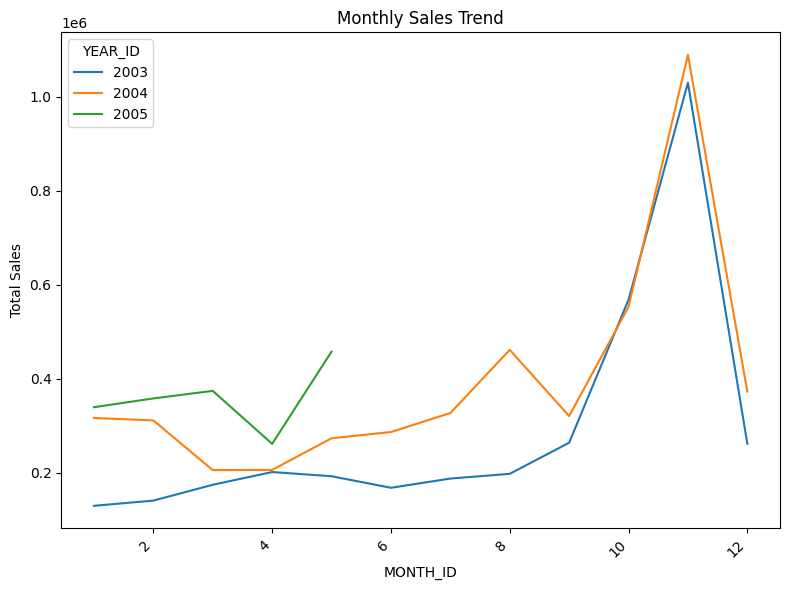

[VIZ 2] Sales by Product Line in 2005  |  type=bar
----------------------------------------------------------------------------------------------------
Generated code:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import math
import datetime
import typing
import pathlib

def build_viz():
    """
    Builds a visualization based on the provided JSON input.

    Returns:
        A JSON-serializable dictionary containing the visualization data and metadata.
    """
    file_abspath = "D:\\Autonomous_Dashboard_Creator_Agent\\data\\sales_data.csv"
    encoding = "cp1252"

    title = "Sales by Product Line in 2005"
    vis_type = "bar"
    why = "Identify top-performing product lines in 2005 to focus on."

    grain = "by PRODUCTLINE"
    filters = ["YEAR_ID = 2005"]
    aggregations = [{"name": "Total Sales", "expr": "SUM(SALES)"}]
    groupby_cols = ["PRODUCTLINE"]
    sort_by = [{"by": "Total Sales", "order": "desc"}]
    limit = None

    encodings 

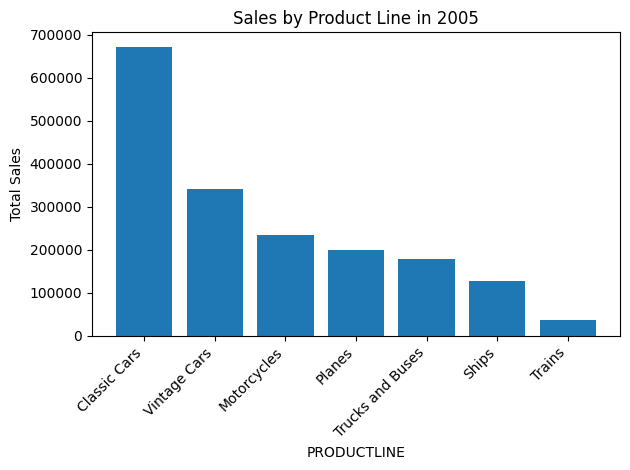

[VIZ 3] Sales by Country in 2005  |  type=map
----------------------------------------------------------------------------------------------------
Generated code:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import math
import datetime
import typing
import pathlib

def build_viz():
    file_abspath = "D:\\Autonomous_Dashboard_Creator_Agent\\data\\sales_data.csv"
    encoding = "cp1252"

    df = pd.read_csv(file_abspath, encoding=encoding)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = pd.to_numeric(df[col], errors="coerce")
        try:
            df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], errors="coerce")
        except KeyError:
            pass

    query_applied = False
    warnings = []

    # Apply filters
    filters = ["YEAR_ID = 2005"]
    for filter_str in filters:
        try:
            if "==" in filter_str:
                col, val = filter_str.split("==")
              

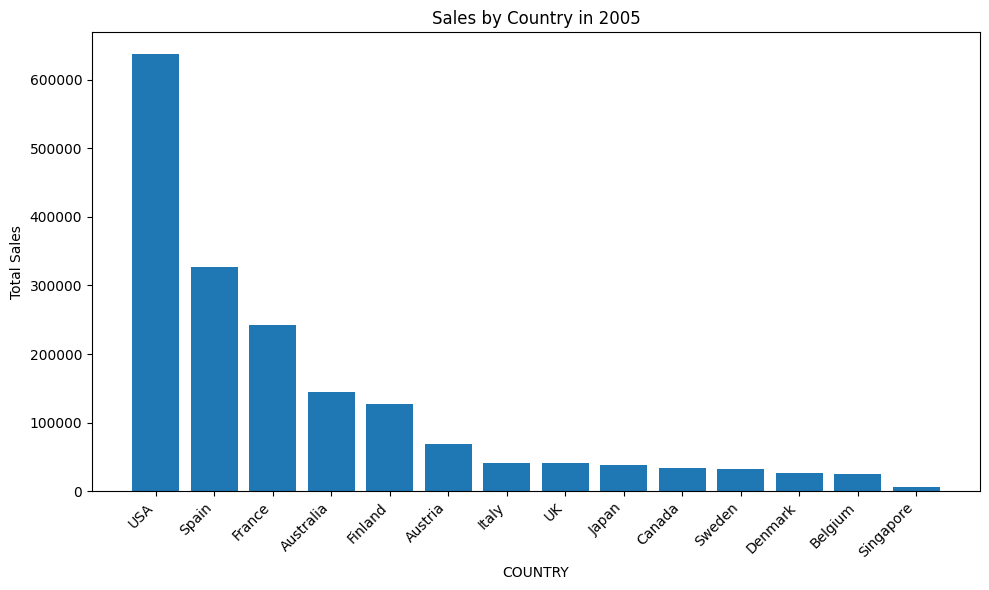

[LLM VIZ] Saved results: outputs\sales_data\sales_data_viz_results.json
[LLM VIZ] Saved function registry: outputs\sales_data\sales_data_viz_functions.json
{'viz_results_path': WindowsPath('outputs/sales_data/sales_data_viz_results.json'), 'viz_functions_path': WindowsPath('outputs/sales_data/sales_data_viz_functions.json')}

VIZ_Codes:
outputs\sales_data\VIZ_codes\monthly_sales_trend.py
outputs\sales_data\VIZ_codes\sales_by_country_in_2005.py
outputs\sales_data\VIZ_codes\sales_by_product_line_in_2005.py


In [5]:
# ---------------------------- Example usage ----------------------------
plan_file = "plans/sales_data_plan.json"
paths = run_visualizations_with_llm(plan_file)
print(paths)

print("\nVIZ_Codes:")
for p in sorted((Path("outputs")/load_json("metadata/sales_data_metadata.json")["dataset"]["name"]/"VIZ_codes").glob("*.py")):
    print(p)

# V1

In [1]:
# ======================= Visualization Agent (LLM-generated code) — v2 =======================
from __future__ import annotations
import json, re, textwrap, ast, io, contextlib, builtins, datetime
from pathlib import Path
from typing import Dict, Any, List, Optional, Tuple

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- LLM init (same as before) ---
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI

load_dotenv()
google_api_key = os.getenv("GOOGLE_API_KEY")
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    api_key=google_api_key,
    temperature=0.15  # lower for simpler code
)

# --------------------------------- IO Helpers ---------------------------------
def load_json(path: str | Path) -> Dict[str, Any]:
    return json.loads(Path(path).read_text(encoding="utf-8"))

def save_json(obj: Any, path: str | Path):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")

def slugify(s: str) -> str:
    return re.sub(r'[^a-zA-Z0-9]+', "_", s).strip("_").lower()[:100]

# -------------------------------- Prompt Builder --------------------------------
def _columns_for_prompt(metadata: Dict[str, Any]) -> List[Dict[str, Any]]:
    cols = []
    for c in metadata.get("columns", []):
        cols.append({
            "name": c["name"],
            "dtype": c.get("dtype"),
            "nullable": c.get("nullable"),
            "semantics": c.get("semantics", []),
            "desc": c.get("description", "")
        })
    return cols

def _compact_records(records: List[Dict[str, Any]], max_rows=18, max_chars=120) -> List[Dict[str, Any]]:
    rows = records[:max_rows]
    out = []
    for r in rows:
        o = {}
        for k,v in r.items():
            s = "" if v is None else str(v)
            o[k] = s[:max_chars]
        out.append(o)
    return out

def build_viz_prompt(viz: Dict[str, Any], metadata: Dict[str, Any], include_kpis: bool=False, kpi_results: Optional[List[Dict[str, Any]]]=None) -> str:
    ds = metadata["dataset"]
    file_abspath = ds.get("file_abspath") or ds.get("file_path") or ds.get("file")
    file_encoding = ds.get("file_encoding") or "utf-8"
    dataset_name = ds.get("name", "dataset")

    cols_desc = _columns_for_prompt(metadata)
    sample = metadata.get("sample", {})
    sample_records = _compact_records(sample.get("records", []), max_rows=18, max_chars=120)

    title = viz.get("title", "")
    vtype = viz.get("type", "")
    why = viz.get("why", "") or viz.get("purpose", "")
    enc = viz.get("encodings", {}) or {}
    query = viz.get("query", {}) or {}

    user_payload = {
        "dataset": {
            "name": dataset_name,
            "file_abspath": file_abspath,
            "encoding": file_encoding,
            "row_count": metadata.get("dataset", {}).get("row_count")
        },
        "schema": cols_desc,
        "visualization": {
            "title": title,
            "type": vtype,
            "why": why,
            "query": query,
            "encodings": enc
        },
        "sample_preview": {
            "columns": sample.get("columns", []),
            "records": sample_records
        }
    }
    if include_kpis and kpi_results:
        user_payload["kpi_results"] = kpi_results[:18]

    # === Keep it simple: tiny function, masks not query, rename aggregated column ===
    sys_rules = """
You are a code generator. Output ONLY valid Python code, no prose, no markdown.

Write ONE zero-argument function: build_viz().

Allowed imports ONLY:
- pandas as pd, numpy as np, matplotlib.pyplot as plt, json, math, datetime, typing, pathlib

Forbidden:
- os, sys, subprocess, shutil, requests, sockets, http, open(), file writes, plt.savefig(), plt.show()
- third-party viz libs (no seaborn/plotly/geopandas).

Implementation rules (KEEP IT SHORT AND SIMPLE):
1) Read the CSV from file_abspath with the given encoding.
2) Convert numeric columns you use with pd.to_numeric(..., errors="coerce"). Parse ORDERDATE with to_datetime if used.
3) Apply filters with BOOLEAN MASKS (NOT df.query). If a filter uses '=' (e.g., "YEAR_ID = 2005"), treat it as '=='.
   Supported operators: =, ==, !=, >=, <=, >, <  (for strings, compare literally; for numbers, cast).
4) Group and aggregate with pandas:
   - For an aggregation like {"name":"Total Sales","expr":"SUM(SALES)"} use .agg({"SALES":"sum"}) and then RENAME the result
     column to "Total Sales".
   - Do NOT validate the presence of the aggregation output column name BEFORE aggregation.
   - Validate ONLY source columns (e.g., "SALES", "YEAR_ID", groupby columns).
5) Sorting and limit are optional but should be applied if present.
6) Build ONE matplotlib figure:
   - type 'line': x vs y; if 'color' enc exists and is a column in the result, plot separate lines per category.
   - type 'bar': x vs y (vertical bars).
   - type 'map': FALLBACK to horizontal bar by region column.
   Use tight_layout(), set title/xlabel/ylabel. Do NOT set custom colors. Do NOT call savefig/show.
7) Return ONLY this dict (JSON-serializable):
{
  "title": <str>,
  "type": <str>,
  "why": <str>,
  "query_applied": {...},      # normalized version of what you executed
  "encodings_used": {...},
  "columns_used": [ ... ],     # source columns used (NOT the renamed agg column)
  "warnings": [ ... ],
  "error": null or <str>,
  "data": {
    "columns": [...],
    "records": [ ... aggregated rows (up to 10000) ... ],
    "row_count": <int>
  }
}
""".strip()

    dev = f"""
Task specifics:
- file_abspath = {json.dumps(file_abspath)}
- encoding = {json.dumps(file_encoding)}
- title = {json.dumps(title)}
- type = {json.dumps(vtype)}
- why = {json.dumps(why)}
- query = {json.dumps(query)}
- encodings = {json.dumps(enc)}

IMPORTANT:
- Keep function ≤ ~80 logical lines. Prefer direct, readable pandas.
- If 'y' encoding field equals an aggregation NAME (e.g., "Total Sales"), PLOT using that renamed column AFTER aggregation.
- Validate only SOURCE columns: groupby + columns referenced inside agg exprs + columns referenced in filters.
- If a filter refers to a string value (e.g., COUNTRY = Spain), compare strings without quotes normalization (literal match).
"""

    prompt = (
        "SYSTEM RULES:\n" + sys_rules + "\n\n"
        "INPUT JSON (metadata + viz + small sample):\n" + json.dumps(user_payload, ensure_ascii=False, indent=2) + "\n\n"
        + dev
    )
    return prompt

# ------------------------------ LLM call ------------------------------
def ask_llm_for_viz_code(llm, prompt: str) -> str:
    messages = [
        {"role": "system", "content": "You write Python code only."},
        {"role": "user", "content": prompt},
    ]
    resp = llm.invoke(messages)
    text = getattr(resp, "content", str(resp)).strip()
    text = re.sub(r"^```(?:python)?\s*|\s*```$", "", text, flags=re.I|re.M)
    return text.strip()

# ------------------------------ Validation ------------------------------
_FORBIDDEN_PATTERNS = [
    r"\bimport\s+os\b",
    r"\bimport\s+sys\b",
    r"\bimport\s+subprocess\b",
    r"\bimport\s+shutil\b",
    r"\brequests\b",
    r"\bsocket\b",
    r"\bhttp\.client\b",
    r"\bopen\s*\(",
    r"\bsavefig\s*\(",
]
_ALLOWED_IMPORTS = {"pandas", "numpy", "json", "math", "datetime", "typing", "pathlib", "matplotlib"}

def validate_viz_code(code: str) -> Tuple[bool, str]:
    for pat in _FORBIDDEN_PATTERNS:
        if re.search(pat, code):
            return False, f"Forbidden construct matched: {pat}"
    try:
        tree = ast.parse(code)
    except Exception as e:
        return False, f"Code is not valid Python: {e}"

    func_found = False
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for alias in node.names:
                root = alias.name.split(".")[0]
                if root not in _ALLOWED_IMPORTS:
                    return False, f"Disallowed import: {alias.name}"
        if isinstance(node, ast.ImportFrom):
            root = (node.module or "").split(".")[0]
            if root and root not in _ALLOWED_IMPORTS:
                return False, f"Disallowed import: from {node.module} import ..."
        if isinstance(node, ast.FunctionDef) and node.name == "build_viz":
            if func_found:
                return False, "Multiple build_viz functions defined."
            if (len(node.args.args) != 0) or node.args.vararg or node.args.kwarg:
                return False, "build_viz must take zero arguments."
            func_found = True
    if not func_found:
        return False, "build_viz() not found."
    return True, ""

# ------------------------------ Sandbox Exec ------------------------------
def _make_safe_import(allowed_roots: set[str]):
    real_import = builtins.__import__
    def _safe_import(name, globals=None, locals=None, fromlist=(), level=0):
        root = name.split(".", 1)[0]
        if root not in allowed_roots:
            raise ImportError(f"Import of '{name}' is not allowed")
        return real_import(name, globals, locals, fromlist, level)
    return _safe_import

def run_viz_in_sandbox(code: str) -> Tuple[Optional[Dict[str, Any]], Optional[str], str]:
    """
    Execute generated viz code with restricted builtins.
    Returns (result_dict, error, captured_stdout).
    """
    safe_import = _make_safe_import(_ALLOWED_IMPORTS)
    safe_builtins = {
        "__import__": safe_import,
        "Exception": Exception,
        "ValueError": ValueError,
        "TypeError": TypeError,
        "len": len,
        "min": min,
        "max": max,
        "sum": sum,
        "range": range,
        "abs": abs,
        "round": round,
        "float": float,
        "int": int,
        "str": str,
        "bool": bool,
        "dict": dict,
        "list": list,
        "set": set,            # <-- allow set
        "tuple": tuple,        # <-- useful
        "enumerate": enumerate,
        "zip": zip,
        "print": print,        # captured
    }
    safe_globals = {
        "__builtins__": safe_builtins,
        "pd": pd,
        "np": np,
        "plt": plt,
        "json": json,
    }
    safe_locals: Dict[str, Any] = {}
    stdout_buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(stdout_buf):
            exec(code, safe_globals, safe_locals)
            fn = safe_locals.get("build_viz") or safe_globals.get("build_viz")
            if not callable(fn):
                return None, "build_viz not callable after exec", stdout_buf.getvalue()
            result = fn()
        if not isinstance(result, dict):
            return None, "build_viz did not return a dict", stdout_buf.getvalue()
        json.dumps(result)
        return result, None, stdout_buf.getvalue()
    except Exception as e:
        return None, f"Execution error: {e}", stdout_buf.getvalue()

# ------------------------------ Orchestrator ------------------------------
def run_visualizations_with_llm(
    plan_path: str | Path,
    metadata_path: Optional[str | Path] = None,
    kpi_results_path: Optional[str | Path] = None,
    include_kpis_in_prompt: bool = False,
    out_root: str | Path = "outputs",
    verbose: bool = True,
    stdout_max: int = 2000,
) -> Dict[str, Path]:
    plan = load_json(plan_path)
    meta_path = metadata_path or plan.get("_meta", {}).get("metadata_path")
    if not meta_path:
        raise ValueError("metadata_path not provided and not present in plan._meta.metadata_path.")
    metadata = load_json(meta_path)

    kpi_results = None
    if include_kpis_in_prompt and kpi_results_path and Path(kpi_results_path).exists():
        kpi_results = load_json(kpi_results_path)

    dataset_name = metadata["dataset"]["name"]
    ds_dir = Path(out_root) / dataset_name
    code_dir = ds_dir / "VIZ_codes"
    data_dir = ds_dir / "visualizations" / "data"
    fig_dir  = ds_dir / "visualizations" / "figures"
    for d in [code_dir, data_dir, fig_dir]:
        d.mkdir(parents=True, exist_ok=True)

    viz_results: List[Dict[str, Any]] = []
    viz_registry: List[Dict[str, Any]] = []
    model_name = getattr(llm, "model", "gemini-2.0-flash")

    for i, viz in enumerate(plan.get("visualizations", []), start=1):
        vslug = slugify(viz.get("title") or f"viz_{i}")
        prompt = build_viz_prompt(viz, metadata, include_kpis=bool(kpi_results), kpi_results=kpi_results)
        code = ask_llm_for_viz_code(llm, prompt)

        if verbose:
            print("\n" + "="*100)
            print(f"[VIZ {i}] {viz.get('title')}  |  type={viz.get('type')}")
            print("-"*100)
            print("Generated code:\n")
            print(code[:20_000])
            print("-"*100)

        valid, why_bad = validate_viz_code(code)
        if not valid:
            (code_dir / f"{vslug}.py").write_text(code, encoding="utf-8")
            entry = {
                "title": viz.get("title"),
                "type": viz.get("type"),
                "error": f"Validation failed: {why_bad}",
                "_diagnostic": {"snippet_head": code[:500]},
            }
            viz_results.append(entry)
            viz_registry.append({
                "title": viz.get("title"),
                "slug": vslug,
                "type": viz.get("type"),
                "code_path": str((code_dir / f"{vslug}.py").resolve()),
                "description": viz.get("why") or viz.get("purpose") or "",
                "created_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                "model": model_name,
                "plan_path": str(Path(plan_path).resolve()),
                "metadata_path": str(Path(meta_path).resolve()),
                "status": "validation_failed"
            })
            if verbose:
                print(f"Validation: ❌ {why_bad}")
            continue

        result, exec_err, stdout = run_viz_in_sandbox(code)
        (code_dir / f"{vslug}.py").write_text(code, encoding="utf-8")

        fig_path = None
        if exec_err:
            status = "execution_error"
            entry = {
                "title": viz.get("title"),
                "type": viz.get("type"),
                "error": exec_err,
                "stdout": (stdout or "")[:stdout_max],
            }
            viz_results.append(entry)
        else:
            status = "ok"
            dat = result.get("data") or {}
            dcols = dat.get("columns") or []
            drows = dat.get("records") or []
            try:
                df_out = pd.DataFrame(drows, columns=dcols)
            except Exception:
                df_out = pd.DataFrame(drows)

            data_path = data_dir / f"{vslug}.csv"
            df_out.to_csv(data_path, index=False, encoding="utf-8")

            # Save/show the most recent fig (if any)
            fig_nums = plt.get_fignums()
            if fig_nums:
                fig = plt.figure(fig_nums[-1])
                fig_path = fig_dir / f"{vslug}.png"
                fig.savefig(fig_path, dpi=120, bbox_inches="tight")
                if verbose:
                    print(f"[Figure saved] {fig_path}")
                plt.show()
                plt.close(fig)
            else:
                if verbose:
                    print("[Warn] No matplotlib figure detected.")

            entry = {
                "title": result.get("title") or viz.get("title"),
                "type": result.get("type") or viz.get("type"),
                "why": result.get("why") or viz.get("why") or viz.get("purpose"),
                "query_applied": result.get("query_applied"),
                "encodings_used": result.get("encodings_used"),
                "columns_used": result.get("columns_used"),
                "warnings": result.get("warnings"),
                "error": result.get("error"),
                "data_path": str(data_path.resolve()),
                "figure_path": str(fig_path.resolve()) if fig_path else None,
                "_stdout": (stdout or "")[:stdout_max]
            }
            viz_results.append(entry)

        viz_registry.append({
            "title": viz.get("title"),
            "slug": vslug,
            "type": viz.get("type"),
            "code_path": str((code_dir / f"{vslug}.py").resolve()),
            "description": viz.get("why") or viz.get("purpose") or "",
            "created_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
            "model": model_name,
            "plan_path": str(Path(plan_path).resolve()),
            "metadata_path": str(Path(meta_path).resolve()),
            "status": status
        })

        if verbose:
            if exec_err:
                print(f"Execution: ❌ {exec_err}")
            else:
                print("Execution: ✅ success")
                print("-"*100)
                print("[Result JSON]")
                print(json.dumps(viz_results[-1], indent=2)[:20_000])

    results_path = ds_dir / f"{dataset_name}_viz_results.json"
    registry_path = ds_dir / f"{dataset_name}_viz_functions.json"
    save_json(viz_results, results_path)
    save_json(viz_registry, registry_path)

    if verbose:
        print("\n" + "="*100)
        print(f"[LLM VIZ] Saved results: {results_path}")
        print(f"[LLM VIZ] Saved function registry: {registry_path}")
        print("="*100)

    return {"viz_results_path": results_path, "viz_functions_path": registry_path}


[VIZ 1] Monthly Sales Trend  |  type=line
----------------------------------------------------------------------------------------------------
Generated code:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import math
import datetime
import typing
import pathlib

def build_viz():
    file_abspath = "D:\\Autonomous_Dashboard_Creator_Agent\\data\\sales_data.csv"
    encoding = "cp1252"
    title = "Monthly Sales Trend"
    viz_type = "line"
    why = "Visualize sales performance by month to identify seasonality and growth trends."
    query = {"grain": "by MONTH & YEAR", "filters": ["YEAR_ID >= 2003"], "aggregations": [{"name": "Total Sales", "expr": "SUM(SALES)"}], "groupby": ["YEAR_ID", "MONTH_ID"], "sort": [{"by": "YEAR_ID", "order": "asc"}, {"by": "MONTH_ID", "order": "asc"}], "limit": None}
    encodings = {"x": {"field": "MONTH_ID", "type": "temporal"}, "y": {"field": "Total Sales", "type": "quantitative"}, "color": {"field": "YEAR_ID", "type":

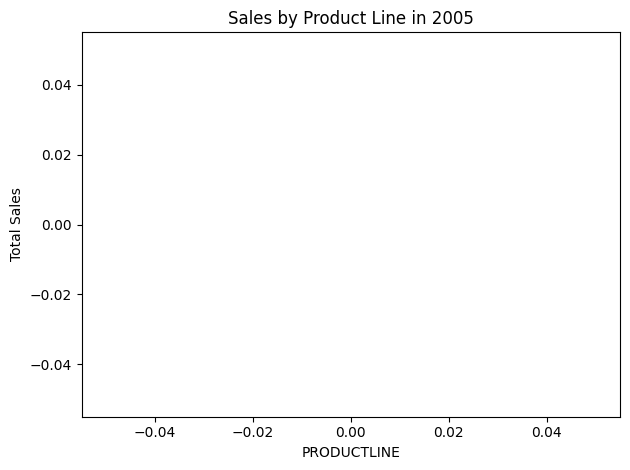

Execution: ✅ success
----------------------------------------------------------------------------------------------------
[Result JSON]
{
  "title": "Sales by Product Line in 2005",
  "type": "bar",
  "why": "Identify top-performing product lines in 2005 to focus on.",
  "query_applied": {
    "grain": "by PRODUCTLINE",
    "filters": [
      "YEAR_ID = 2005"
    ],
    "aggregations": [
      {
        "name": "Total Sales",
        "expr": "SUM(SALES)"
      }
    ],
    "groupby": [
      "PRODUCTLINE"
    ],
    "sort": [
      {
        "by": "Total Sales",
        "order": "desc"
      }
    ],
    "limit": null
  },
  "encodings_used": {
    "x": {
      "field": "PRODUCTLINE",
      "type": "string"
    },
    "y": {
      "field": "Total Sales",
      "type": "quantitative"
    },
    "color": {
      "field": null,
      "type": "string",
      "legend": true
    },
    "facet": {
      "field": null,
      "type": "string"
    }
  },
  "columns_used": [
    "SALES",
    "YEA

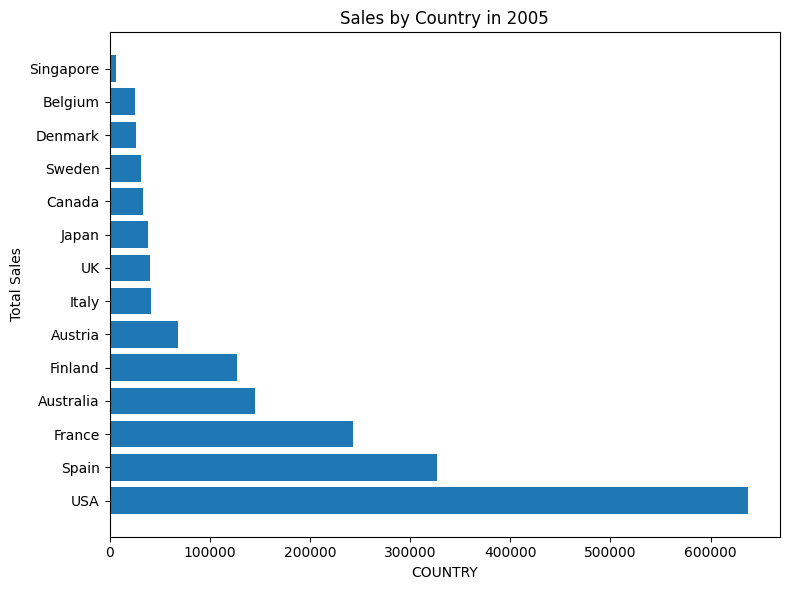

Execution: ✅ success
----------------------------------------------------------------------------------------------------
[Result JSON]
{
  "title": "Sales by Country in 2005",
  "type": "map",
  "why": "Identify key markets and potential areas for expansion.",
  "query_applied": {
    "grain": "by COUNTRY",
    "filters": [
      "YEAR_ID = 2005"
    ],
    "aggregations": [
      {
        "name": "Total Sales",
        "expr": "SUM(SALES)"
      }
    ],
    "groupby": [
      "COUNTRY"
    ],
    "sort": [
      {
        "by": "Total Sales",
        "order": "desc"
      }
    ],
    "limit": null
  },
  "encodings_used": {
    "x": {
      "field": "COUNTRY",
      "type": "string"
    },
    "y": {
      "field": "Total Sales",
      "type": "quantitative"
    },
    "color": {
      "field": "Total Sales",
      "type": "quantitative",
      "legend": true
    },
    "facet": {
      "field": null,
      "type": "string"
    }
  },
  "columns_used": [
    "SALES",
    "YEAR_ID"

In [2]:
# ---------------------------- Example usage ----------------------------
# Make sure these paths match your files
plan_file = "plans/sales_data_plan.json"
# If not provided, code will read metadata path from plan._meta.metadata_path
paths = run_visualizations_with_llm(plan_file)
print(paths)

# Optional: preview what was generated
print("\nVIZ_Codes:")
for p in sorted((Path("outputs")/load_json("metadata/sales_data_metadata.json")["dataset"]["name"]/"VIZ_codes").glob("*.py")):
    print(p)


[VIZ 1] Monthly Sales Trend  |  type=line
----------------------------------------------------------------------------------------------------
Generated code:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import math
import datetime
import typing
import pathlib

def build_viz():
    file_abspath = "D:\\Autonomous_Dashboard_Creator_Agent\\data\\sales_data.csv"
    encoding = "cp1252"
    title = "Monthly Sales Trend"
    viz_type = "line"
    why = "Visualize sales performance by month to identify seasonality and growth trends."
    query = {"grain": "by MONTH & YEAR", "filters": ["YEAR_ID >= 2003"], "aggregations": [{"name": "Total Sales", "expr": "SUM(SALES)"}], "groupby": ["YEAR_ID", "MONTH_ID"], "sort": [{"by": "YEAR_ID", "order": "asc"}, {"by": "MONTH_ID", "order": "asc"}], "limit": None}
    encodings = {"x": {"field": "MONTH_ID", "type": "temporal"}, "y": {"field": "Total Sales", "type": "quantitative"}, "color": {"field": "YEAR_ID", "type":

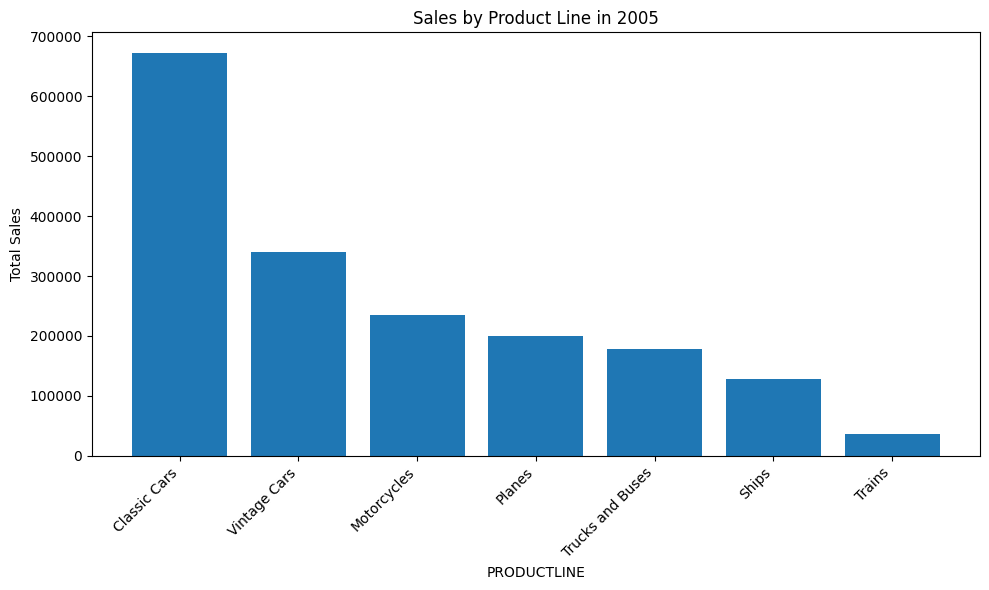

Execution: ✅ success
----------------------------------------------------------------------------------------------------
[Result JSON]
{
  "title": "Sales by Product Line in 2005",
  "type": "bar",
  "why": "Identify top-performing product lines in 2005 to focus on.",
  "query_applied": {
    "grain": "by PRODUCTLINE",
    "filters": [
      "YEAR_ID = 2005"
    ],
    "aggregations": [
      {
        "name": "Total Sales",
        "expr": "SUM(SALES)"
      }
    ],
    "groupby": [
      "PRODUCTLINE"
    ],
    "sort": [
      {
        "by": "Total Sales",
        "order": "desc"
      }
    ],
    "limit": null
  },
  "encodings_used": {
    "x": {
      "field": "PRODUCTLINE",
      "type": "string"
    },
    "y": {
      "field": "Total Sales",
      "type": "quantitative"
    },
    "color": {
      "field": null,
      "type": "string",
      "legend": true
    },
    "facet": {
      "field": null,
      "type": "string"
    }
  },
  "columns_used": [
    "SALES",
    "YEA

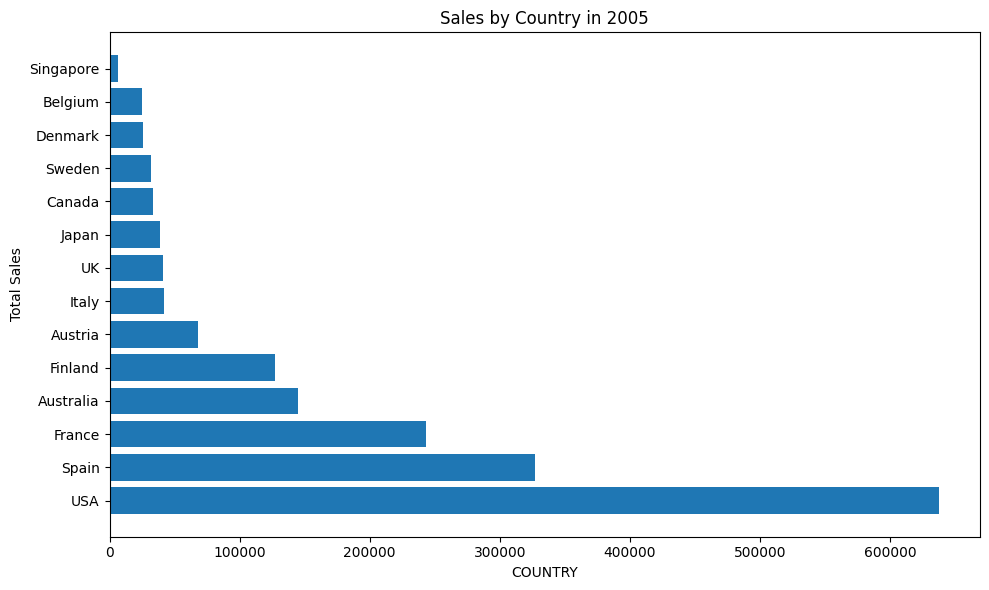

Execution: ✅ success
----------------------------------------------------------------------------------------------------
[Result JSON]
{
  "title": "Sales by Country in 2005",
  "type": "map",
  "why": "Identify key markets and potential areas for expansion.",
  "query_applied": {
    "grain": "by COUNTRY",
    "filters": [
      "YEAR_ID = 2005"
    ],
    "aggregations": [
      {
        "name": "Total Sales",
        "expr": "SUM(SALES)"
      }
    ],
    "groupby": [
      "COUNTRY"
    ],
    "sort": [
      {
        "by": "Total Sales",
        "order": "desc"
      }
    ],
    "limit": null
  },
  "encodings_used": {
    "x": {
      "field": "COUNTRY",
      "type": "string"
    },
    "y": {
      "field": "Total Sales",
      "type": "quantitative"
    },
    "color": {
      "field": "Total Sales",
      "type": "quantitative",
      "legend": true
    },
    "facet": {
      "field": null,
      "type": "string"
    }
  },
  "columns_used": [
    "SALES",
    "YEAR_ID"

In [3]:
# ---------------------------- Example usage ----------------------------
plan_file = "plans/sales_data_plan.json"
meta_file = "metadata/sales_data_metadata.json"
outputs = run_visualizations_with_llm(plan_file, meta_file, include_kpis_in_prompt=False, verbose=True)
print(outputs)